# COMP1117: Computer programming - Tutorial 8

Welcome to Tutorial 8!

In [1]:
!pip install matplotlib numpy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Tutorial Exercises

### 1. Factorial
$$a_n = n \times a_{n-1}$$

$$a_0 = 1$$

A little bit more about factorial.

The total number of ways to arrange n distinct objects in a sequence is n factorial, denoted as n!.

```
[1,2,3]
[1,3,2]
[2,1,3]
[2,3,1]
[3,1,2]
[3,2,1]
```

In [2]:
def factorial(n):
    """Return n! (n factorial) for non-negative integer n."""
    if n == 0:
        return 1
    else:
        return n * factorial(n - 1)
    
if __name__ == "__main__":
    print(factorial(5))  # Output: 120

120


Let's check the recursive calls with [Python Tutor](https://pythontutor.com/visualize.html#code=def%20fact%28n%29%3A%0A%20%20%20%20if%20n%20%3D%3D%200%3A%0A%20%20%20%20%20%20%20%20return%201%0A%20%20%20%20return%20n*fact%28n-1%29%0A%20%20%20%20%0Aprint%28fact%284%29%29&curInstr=0&mode=display&origin=opt-frontend.js&py=311)



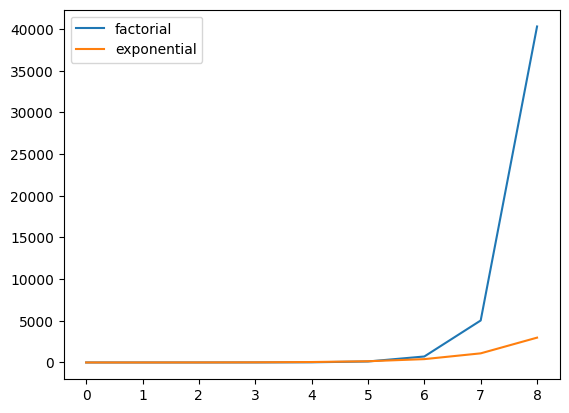

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math

x = list(range(0, 9))
y = [factorial(i) for i in x]
z = list(map(math.exp, x))

x = np.array(x)
y = np.array(y)
z = np.array(z)

plt.plot(x, y, label = "factorial") # fact(n)
plt.plot(x, z, label = "exponential") # e^n
plt.legend()

Asymptotical behaviour of n! (Stirling's approximation):

$$n! \approx \sqrt{2 \pi n} \left(\frac{n}{e}\right)^n$$

When $n \rightarrow \infty$

You will see this again in some future courses (algorithms, probability ...)

### 2. Combination

In mathematics, combinations refer to the combination of n things taken k at a time without
repetition. There is a recursive formula related to combinations:

$$ {n \choose k} = {n-1 \choose k-1} + {n-1 \choose k}$$

$$C(n, k) = C(n-1, k-1) + C(n-1, k)$$

And ${n \choose 0} = {n \choose n} = 1$, ${n \choose k} = 0$ if $k > n$.




In [4]:
def C(n, k):
    """Return the number of combinations of n items taken k at a time."""
    if k == 0 or n == k:
        return 1
    elif k > n:
        return 0

    return C(n-1, k-1) + C(n-1, k)
    
if __name__ == "__main__":
    print(C(5, 2))  # Output: 10
    print(C(2, 5))  # Output: 0

10
0


A little bit more about combinations.

$${n \choose k} = \frac{n!}{k!(n-k)!}$$

An combinatorial interpretation of $ {n \choose k} = {n-1 \choose k-1} + {n-1 \choose k} $

Choose a specific item A from the n items. 
- If A is included in the selection, we need to choose k-1 items from the remaining n-1 items. There are ${n-1 \choose k-1}$ ways to do this.
- If A is not included in the selection, we need to choose k items from the remaining n-1 items. There are ${n-1 \choose k}$ ways to do this.

You will learn more about combinatorics in future courses (COMP2121, STAT2601 ...).


### 3. Radix/Base conversion

Complete the code below by defining a recursive function `convert_base(n, b)` which converts a
decimal integer n to a string in base b. You may assume the input n is an integer in decimal and
the input b is in the range 2 to 16, inclusively.

35 = 2 * 17 + 1 \
17 = 2 * 8 + 1 \
8 = 2 * 4 + 0 \
4 = 2 * 2 + 0 \
2 = 2 * 1 + 0 \
1 = 2 * 0 + 1 

convert_base(35, 2) = "100011"
convert_base(17, 2) = "10001"


$0 1 10 11 100 101 110 111 1000 1001 1010 1011 1100 1101 1110 1111$

$35 = 3 \times 10^1 + 5 \times 10^0$

$x = a_0 * 10 ^ 0 + a_1 * 10 ^ 1 + ... + a_n * 10 ^ n$


$x = b_0 * 2 ^ 0 + b_1 * 2 ^ 1 + ... + b_n * 2 ^ n$

$x = b_0 * 2 ^ 0 + 2 * (b_1 * 2 ^ 0 + ... + b_n * 2 ^ {n-1})$

$x = b_0 * 2 ^ 0 + 2 * (b_1 * 2 ^ 0 + 2* (b_2 * 2^0 ... + b_n * 2 ^ {n-2}))$

A = 10, B = 11, C = 12, D = 13, E = 14, F = 15

In [7]:
helper = "0123456789ABCDEF"

def convert_base(n, b) -> str: # convert_base(17, 2)
    # n = 35, b = 2
    """Convert non-negative integer n to its representation in base b."""
    if n == 0:
        return ""
    return convert_base(n // b, b) + helper[n % b]


if __name__ == "__main__":
    print(convert_base(10, 2))  # Output: '1010'
    print(convert_base(255, 16))  # Output: 'FF'

1010
FF


In [8]:
a = 0xFF
b = 0b110
c = 0o77
d = 1_000_000
print(d)
e = 1e6
print(e)

1000000
1000000.0


### 4. Sum of digits

Summing up the digits of an integer n in decimal representation with recursion.

1234 -> $4 + 3 + 2 + 1 = 10$

In [10]:
def sum_digit(n):
    if n < 10:
        return n
    return sum_digit(n // 10) + n % 10

print(sum_digit(1234))

10


In [ ]:
n = 1234

temp_str = str(n)

digit_sum = sum(map(int, temp_str)) # "1234"

print(digit_sum)

10


### 5. Weighted sum of digits (Luhn Sum)

Summing up the digits of an integer n with twice the odd digits (counting from right to left).

E.g., 1234 -> $4\times2 + 3 + 2\times2 + 1 = 16$

In [13]:
def sum_odd(n):
    if n < 10:
        return n * 2
    else:
        return sum_even(n // 10) + (n % 10)*2
    
def sum_even(n):
    if n < 10:
        return n
    else:
        return sum_odd(n // 10) + (n % 10)

In [14]:
def luhn_sum(n):
    return sum_odd(n)

print(luhn_sum(1234))

16


1234 \
sum_odd(1234) = sum_even(123) + 4 * 2 \
sum_even(123) = sum_odd(12) + 3 \
sum_odd(12) = sum_even(1) + 2 * 2 \
sum_even(1) = 1

### 6. Palindrome with recursion

Last time, we have learned how to check if a string is a palindrome with `s == s[::-1]`. Now, we will implement a recursive function to check if a string is a palindrome.

In [3]:
def is_palindrome(s,l,r):
    if l >= r:
        return True
    return s[l] == s[r] and is_palindrome(s, l+1, r-1)

if __name__ == "__main__":
    test_str = "racecar"
    print(is_palindrome(test_str, 0, len(test_str)-1))

True


### 7. Ackermann function (optional)

Implement Ackermann function by recursive function calls. Ackermann function is defined as follows:

$$ A(m,n) = \begin{cases} n + 1 &\text{if}& m = 0 \\
A(m - 1, 1) &\text{if}& m > 0 \text{ and } n = 0 \\
A(m - 1, A(m, n - 1)) &\text{if}& m > 0 \text{ and } n > 0
\end{cases}

In [ ]:
def Ackermann(m, n):
    """Return the Ackermann function A(m, n)."""
    if m == 0:
        return n+1
    elif m > 0 and n == 0:
        return Ackermann(m-1,1)
    else:
        return Ackermann(m-1, Ackermann(m,n-1))
    
if __name__ == "__main__":
    print(Ackermann(1, 2))  
    print(Ackermann(4, 0))  

Does this function well-defined for all non-negative integers m and n? 

You may wonder why we care about such a weird function.
The Ackermann function is a classic example in computer science and mathematics that illustrates the concept of computability. It can also be used to test the optimization and efficiency of compilers and interpreters, as it grows very quickly even for small inputs.